In [ ]:
using BifurcationKit, LinearAlgebra,Plots
const BK = BifurcationKit
#variable transformation that ensure solutions are physical
function var_transform(ϕp,X,ψ,p)
    (;λ)=p
    ucharge,usalt,ucat,uκ=X
    ϕcharge=(1-ϕp)/(1+exp(ucharge))
    ϕOH=ϕcharge/(1+exp(usalt))
    ϕsalt=ϕcharge*exp(usalt)/(1+exp(usalt))
    ϕcat=ϕsalt*exp(ucat)/(1+exp(ucat))
    ϕan=ϕsalt*1/(1+exp(ucat))
    κ=sqrt(λ)/(1+exp(uκ))
    μDH=-λ/(8*π)*κ/(1+κ)

    return (ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH)
end
# Define the free energy
function f(ϕ,p)
    (; χ, λ, Npoly,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH=ϕ
    
    
    ϕs=1-ϕp-ϕcat-ϕan-ϕOH
    fmix=ϕp*log(ϕp)/Npoly+ϕs*log(ϕs)+ϕcat*log(ϕcat)+ϕan*log(ϕan)+ϕOH*log(ϕOH)
    fFH = χ * ϕp *ϕs
    fDH = μDH*(-κ^2/λ+zcat^2*ϕcat+zan^2*ϕan+zp^2*Npoly*ϕp+ϕOH)-(1/(4π)) * (log(1 +κ) - κ+ κ^2/2)+ψ*(zcat*ϕcat-zan*ϕan-ϕOH+zp*ϕp)

    return fmix+fFH+fDH
end
#electroneutrality constraints
function electroneutrality(ϕ,p)
    (; χ, λ, Npoly,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,_=ϕ

    return [zcat*ϕcat-zan*ϕan-ϕOH+zp*ϕp,-κ^2/λ+zcat^2*ϕcat+zan^2*ϕan+zp^2*Npoly*ϕp+ϕOH]
end

#chemical potentials
function μ_values(ϕ, p)
    (; χ, Npoly,λ,zp,zcat,zan) = p
    ϕp,ϕcat,ϕan,ϕOH,ψ,κ,μDH=ϕ

    ϕs=1-ϕp-ϕcat-ϕan-ϕOH
    μ_p = log(ϕp)/Npoly-log(ϕs)+χ*(ϕs-ϕp)+1/Npoly-1+zp*(ψ+zp*Npoly*μDH)
    μ_cat = log(ϕcat/ϕs)-χ*ϕp+zcat*(ψ+zcat*μDH)
    μ_an=log(ϕan/ϕs)-χ*ϕp+zan*(-ψ+zan*μDH)
    μ_OH = log(ϕOH/ϕs)-χ*ϕp-ψ+μDH

    return [μ_p,μ_cat,μ_an,μ_OH]
end

# Coexistnece equations to solve
function coexistence_system(X, p)
    (;exphiP1,Np,zcat,zan)=p
    F=similar(X)
    uphiP2= X[5]
    ϕp1 = 10^exphiP1
    ϕp2 = exp(uphiP2)/(1+exp(uphiP2))
    
    ϕvar1=var_transform(ϕp1,X[1:4],0,p)
  
    ϕvar2=var_transform(ϕp2,X[6:9],X[10],p)

    f1 = f(ϕvar1,p)
    f2 = f(ϕvar2,p)

    μ1 = μ_values(ϕvar1,p)
    μ2 = μ_values(ϕvar2,p)


    dϕp=ϕp1 - ϕp2
    dϕcat=ϕvar1[2]-ϕvar2[2]
    dϕan=ϕvar1[3]-ϕvar2[3]
    dϕOH=ϕvar1[4]-ϕvar2[4]

    F[1]=μ1[1]-μ2[1]
    F[2]=μ1[2]-μ2[2]
    F[3:4]=electroneutrality(ϕvar1,p) #defines electric field jump and κ
    F[5] = ((f1 - f2) - μ1[1]*dϕp - dϕcat*μ1[2]-dϕan*μ1[3]-dϕOH*μ1[4]) #defined \phip2
    F[6]=μ1[3]-μ2[3] # defines OH
    F[7]=μ1[4]-μ2[4] # defines cat 2
    F[8]= (Np-ϕvar1[1])*(ϕvar2[2]*zan-ϕvar2[3]*zcat)/dϕp+(ϕvar2[1]-Np)*(ϕvar1[2]*zan-ϕvar1[3]*zcat)/dϕp# overall condition
    F[9:10]=electroneutrality(ϕvar2,p)
    return F
end

Nmonomer=50.
meanϕP=1.5*1e-3*Nmonomer/55.35
# System parameters
p = (exphiP1 = log10(meanϕP), # Initial guess
    χ =0.875,
    Np=1.5*1e-3*Nmonomer/55.35,
    λ = 160,#26.68,
    Npoly = Nmonomer,
    zp=2/Nmonomer,zcat=1.,zan=1)

# Initial guess
X0 = [1.6337310789746535, 8.009342931872826, 0.00017419649593560703, 0.3889257048797199, -0.0924546446784392, 1.1861505360989448, 7.864675170336844, -0.31365621047513365, 0.506120820907485, 0.1569152034855347]
X0top=[3.4679437338764183, 6.321018660689539, 4.077671459348683e-17, 1.558030529853911, -0.11503461231533173, 2.6044674821520104, 5.904602988221793, -1.14315296016782, 1.1799407656513001, 0.5715764800839099]
X0down=[8.996302101481373, 0.24839555644576086, -8.011710857504563e-17, 4.303761296134204, -0.011274332134985887, 3.1879610565713645, -0.4424993319458687, -6.094680482406037, 1.3892759157266497, 3.047340241203018]

10-element Vector{Float64}:
  8.996302101481373
  0.24839555644576086
 -8.011710857504563e-17
  4.303761296134204
 -0.011274332134985887
  3.1879610565713645
 -0.4424993319458687
 -6.094680482406037
  1.3892759157266497
  3.047340241203018

In [2]:
# just one interesting feature to look at
function total_salt(ϕp1,X,p)
    (;Np) = p
    ϕvar1=var_transform(ϕp1,X[1:4],0,p)
    uphiP2= X[5]
    ϕp2 = exp(uphiP2)/(1+exp(uphiP2))
    ϕvar2=var_transform(ϕp2,X[6:9],X[10],p)
    
    ν=(Np-ϕp2)/(ϕp1-ϕp2)

    return ν*ϕvar1[2]+(1-ν)*ϕvar2[2]
end

total_salt (generic function with 1 method)

In [3]:
opt_newton = NewtonPar(tol = 1e-9, verbose = true, max_iterations = 50)

prob = BifurcationProblem(coexistence_system, X0, p, (@optic _.exphiP1);record_from_solution =(x, u; k...) ->total_salt(10^u,x,p)) # defines the continuation problem

println("Solving initial system at phiP1=", p.exphiP1)
sol = BK.solve(prob, Newton(), opt_newton)
u0 = sol.u
println("Initial solution = ", u0)

Solving initial system at phiP1=-2.8680563618230415

┌─────────────────────────────────────────────────────┐
│ Newton step         residual      linear iterations │
├─────────────┬──────────────────────┬────────────────┤
│       0     │       1.6024e-01     │        0       │
│       1     │       5.3038e-02     │        1       │
│       2     │       3.0599e-03     │        1       │
│       3     │       1.0346e-04     │        1       │
│       4     │       4.6242e-09     │        1       │
│       5     │       4.3666e-15     │        1       │
└─────────────┴──────────────────────┴────────────────┘
Initial solution = [2.364600952009605, 7.36640218995323, -1.1762846209341417e-16, 0.8804036421077124, -0.14966851905597356, 1.7861200632180878, 7.1518388409360165, -0.4881066837971837, 0.6728549803796605, 0.24405334189859273]


In [4]:
prob = re_make(prob, u0=u0)

opts_br = ContinuationPar(dsmin=1e-4, dsmax=0.02, ds=0.001,save_sol_every_step=1,
                          p_min = -6., p_max = -0.1,
                          max_steps = 10000,
                          newton_options = NewtonPar(tol=1e-10, max_iterations=2), detect_bifurcation=1)
brzp= BK.continuation(prob, PALC(), opts_br,bothside=true);

In [5]:
# (I) dilute phase, (II) dense phase 
ϕpI=Vector{Float64}() 
ϕmI=Vector{Float64}()
ϕmII=Vector{Float64}()
ϕplI=Vector{Float64}()
ϕplII=Vector{Float64}()
νvec=Vector{Float64}()
totϕp=Vector{Float64}()
totϕsalt=Vector{Float64}()

ϕOHI=Vector{Float64}()

ϕpII=Vector{Float64}()
ϕOHII=Vector{Float64}()
for el in brzp.sol
    Z=exp(el.x[5])/(1+exp(el.x[5]))
    if Z<10^el.p
        ϕvec=var_transform(10^el.p,el.x[1:4],0,p)
        append!(ϕpII,10^el.p)
        append!(ϕplII,ϕvec[2])
        append!(ϕmII,ϕvec[3])
        append!(ϕOHII,ϕvec[4])
        
        append!(ϕpI,Z)
        ν=(p.Np-ϕpII[end])/(ϕpI[end]-ϕpII[end])
        ϕvec=var_transform(ϕpI[end],el.x[6:end-1],el.x[end],p)
        append!(ϕplI,ϕvec[2])
        append!(ϕmI,ϕvec[3])
        append!(ϕOHI,ϕvec[4])
        append!(totϕsalt,ν*ϕplI[end]+(1-ν)*ϕplII[end])
        append!(νvec,ν)
    end
    
end

In [6]:
size(phip_plot)

UndefVarError: UndefVarError: `phip_plot` not defined

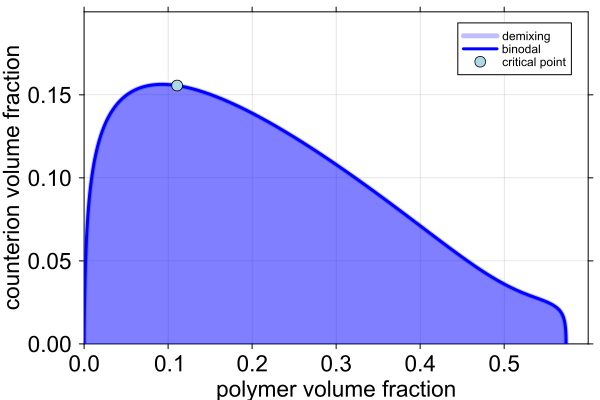

In [7]:
default(fontfamily="Arial",framestyle=:box, label=nothing, grid=true,tickfont = font(15, "Arial"),tick_direction=:out,thickness_scaling = 1.)

phip_plot=vcat(ϕpI[end:-1:1],ϕpII)
phim_plot=vcat(ϕmI[end:-1:1],ϕmII)

plot(phip_plot,phim_plot,color=:blue,ylabel="counterion volume fraction",guidefont=font(15, "Arial"),xlabel="polymer volume fraction",lw=5.,ribbon=(0,-phim_plot),alpha=0.25,label="demixing")
plot!(phip_plot,phim_plot,color=:blue,lw=3,label="binodal")

#plot!(ϕpII,ϕmII,color=:blue,ylabel="counterions",xlabel="ϕp",lw=2)

#critical point 
p=scatter!([ϕpI[1]],[ϕmI[1]],m=6,color=:lightblue,ylim=(0,0.2),xlim=(0,0.6),label="critical point")
savefig("diagram_monovalent.svg")
display(p)

In [39]:
using DelimitedFiles
M=hcat(ϕpI,ϕmI,ϕplI,ϕOHI,ϕpII,ϕmII,ϕplII,ϕOHII,νvec)
open("bifurcation_diagram.txt","w") do io
    writedlm(io,M,',')
end
